**NB**: Remember to set the `PYTHONPATH` environment variable to `$DISPATCH_DIR/utilities/python`, where `$DISPATCH_DIR` is the location of your DISPATCH repository.

This notebook assumes you have already compiled DISPATCH for the 1-D MHD shock experiment (`make`) and run the code (`./dispatch.x`) successfully.
The data can be found in the `data` directory.


In [1]:
def patch_grid_edges(p, slicedir, truecoords=True):
    """
    Using the corners of the patch, create a matplotlib patch that draws
    the grid edges.

    """

    from matplotlib.patches import Rectangle, Wedge

    lo_corners = []
    hi_corners = []
    origin = p.llc_cart
    for o,s in zip(origin,p.size):
        lo_corners.append(o)
        hi_corners.append(o + s)
    active_corners = lo_corners, hi_corners

    if truecoords:
        if slicedir == 1:
            llx, urx = active_corners[0][1], active_corners[1][1]
            lly, ury = active_corners[0][2], active_corners[1][2]
        elif slicedir == 2:
            llx, urx = active_corners[0][0], active_corners[1][0]
            lly, ury = active_corners[0][2], active_corners[1][2]
        elif slicedir == 3:
            llx, urx = active_corners[0][0], active_corners[1][0]
            lly, ury = active_corners[0][1], active_corners[1][1]
    else:
        if slicedir == 1:
            llx, urx = p.llc_cart[1], p.llc_cart[1] + p.size[1]
            lly, ury = p.llc_cart[2], p.llc_cart[2] + p.size[2]
        elif slicedir == 2:
            llx, urx = p.llc_cart[0], p.llc_cart[0] + p.size[0]
            lly, ury = p.llc_cart[2], p.llc_cart[2] + p.size[2]
        elif slicedir == 3:
            llx, urx = p.llc_cart[0], p.llc_cart[0] + p.size[0]
            lly, ury = p.llc_cart[1], p.llc_cart[1] + p.size[1]

    if p.mesh_type == 'Cartesian' or truecoords: # Cartesian or Cartesian-like
        edges = Rectangle((llx,lly),width=(urx-llx),height=(ury-lly),fc='none',lw=1.0,
                          ec='0.7',linestyle='dashed',zorder=0.01/min(p.ds)+0.1)
    elif p.mesh_type == 'spherical':
        thetamin = round(active_corners[0][2]*180.0/np.pi,3)
        thetamax = round(active_corners[1][2]*180.0/np.pi,3)
        llx, urx = active_corners[0][0], active_corners[1][0]
        edges = Wedge((p.pos[0]*scaling,p.pos[1]*scaling),urx,thetamin,thetamax,width=(urx-llx),fc='none',
                      lw=1.0,ec='k',linestyle='dotted',zorder=0.01/min(p.ds)+0.1)
    elif p.mesh_type == 'cylindrical':
        phimin = round(active_corners[0][2]*180.0/np.pi,3)
        phimax = round(active_corners[1][2]*180.0/np.pi,3)
        llx, urx = active_corners[0][1], active_corners[1][1]
        edges = Wedge((p.pos[0]*scaling,p.pos[1]*scaling),urx,phimin,phimax,width=(urx-llx),fc='none',
                      lw=1.0,ec='k',linestyle='dotted',zorder=0.01/min(p.ds)+0.1)

    return edges

In [2]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib import cm
import dispatch
import dispatch.select
import itertools

plt.interactive(True)

In [3]:
plt.rcParams['figure.figsize'] = (9.5, 8)

First, read a snapshot.

In [27]:
snap = dispatch.snapshot(iout=19,run='')
print "no. patches:",len(snap.patches)
p0 = snap.patches[0]
print "ID:",p0.id
print "Position of patch centre:",p0.position
print "Snapshot time of patch:",p0.time
print "No. steps taken:",p0.istep
print "Total no. cells (incl. ghost cells):",p0.gn
print "Patch size:",p0.size
print "Domain size:",p0.box
print "Patch mesh type:",p0.mesh_type
print "No. ghost cells:",p0.ng

no. patches: 180
ID: 1
Position of patch centre: [ 0.5         0.505      -2.96705981]
Snapshot time of patch: 1.1932
No. steps taken: 897
Total no. cells (incl. ghost cells): [ 1 21 32]
Patch size: [1.         0.20999999 0.34906586]
Domain size: [1.         2.0999999  6.28318548]
Patch mesh type: cylindrical
No. ghost cells: [0 2 2]


In [6]:
print p0.idx.vars

{0: 'd', 1: 'e', 2: 'et', 3: 'px', 4: 'py', 5: 'pz', 6: 'bx', 7: 'by', 8: 'bz', 9: 'phi'}


Here are the MHD variables stored in this patch and their associated index in the data. `px` is the x-component of momentum, etc.

You don't have to remember these indices because you can always retrieve them using aliases, e.g., `patch.idx.d`.

0.0 0.00063705625


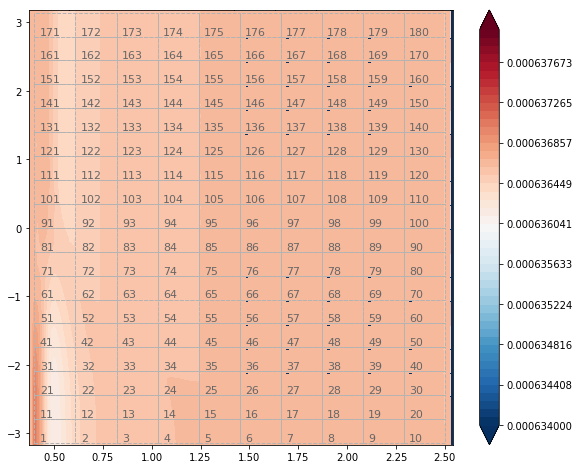

In [28]:
fig = plt.figure(1) # create figure instance
fig.clf()
cax = fig.add_subplot(1,1,1)
levels = np.linspace(6.34e-4,6.38e-4,num=50)
#levels = np.linspace(6e-4,7.6e-4,num=50)
#levels = np.linspace(-1.0e-7,5e-8,num=50)
gqmin, gqmax = 1.0e99, -1.0e99
for p in snap.patches:
    rho = p.var(p.idx.d)
    #py = p.var(p.idx.py)
    gqmin = min(gqmin,rho.min())
    gqmax = max(gqmax,rho.max())
    #print p.id, p.position, rho.min(), rho.max()
    plt.contourf(np.array(p.y),np.array(p.z),rho.squeeze().T,levels,cmap=cm.RdBu_r,extend='both',zorder=0.0)
    edges = patch_grid_edges(p,1,truecoords=True)
    cax.add_patch(edges)
    offset = [2*x for x in p.ng]
    offset[0] = 0
    gn_xpos = p.y[offset[1]]
    gn_ypos = p.z[offset[2]]
    cax.annotate(str(p.id),(gn_xpos,gn_ypos),color='0.4',fontsize=11,zorder=min(p.ds))
    
plt.colorbar()
print gqmin,gqmax

In [6]:
p0.ng

array([0, 2, 2])

25
(1, 21, 32)
0.0 0.0006366179


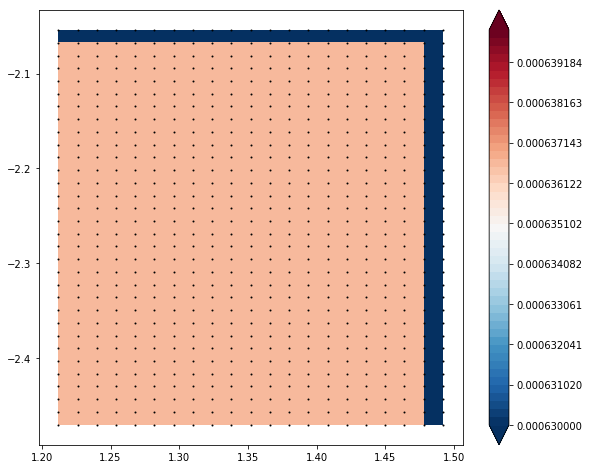

In [26]:
p0 = snap.patches[25-1]
print p0.id
fig = plt.figure(2)
fig.clf()
q = p0.var(p0.idx.d); levels = np.linspace(6.3e-4,6.4e-4,num=50)
#q = p0.var(p0.idx.py); levels = np.linspace(-5e-7,5e-7,num=50)
#q = p0.var(p0.idx.pz); levels = np.linspace(5.0e-4,6.0e-4,num=50)
#q = p0.var(p0.idx.e); levels = np.linspace(1.0e-2,2.1e-2,num=50)
n1, n2, n3 = q.shape
print q.shape
print q.min(),q.max()
plt.contourf(p0.y,p0.z,q.squeeze().T,levels,cmap=cm.RdBu_r,extend='both')
plt.colorbar()
yy, zz = np.meshgrid(p0.y,p0.z,indexing='ij')
plt.scatter(yy,zz,c='k',s=1.0,marker='o')

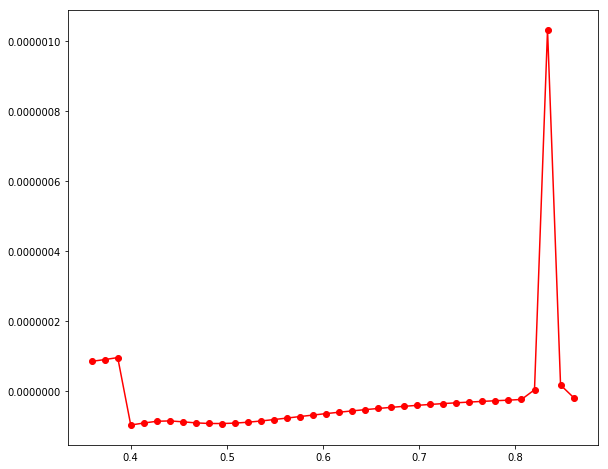

In [227]:
q2 = q[0,:,57]
fig = plt.figure(3)
fig.clf()
plt.plot(p0.y[:n2-1],q2[:n2-1],'ro-')
#plt.plot(p0.z,q[0,3,:],'bo')
#plt.plot(p0.z,q[0,4,:],'go')